In [1]:
# Libraries import kar rahe hain
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset load karna
data = pd.read_csv('Placement_Data_Full_Class.csv')

# Shuru ki 5 rows dekhna
print("Dataset ki pehli 5 rows:")
display(data.head())

# Dataset ka structure aur details dekhna
print("\nDataset ki Information:")
data.info()

# Missing values (khali jagah) check karna
print("\nMissing Values Count:")
print(data.isnull().sum())

Dataset ki pehli 5 rows:


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0



Dataset ki Information:
<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    str    
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    str    
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    str    
 6   hsc_s           215 non-null    str    
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    str    
 9   workex          215 non-null    str    
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    str    
 12  mba_p           215 non-null    float64
 13  status          215 non-null    str    
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), str(8)
memory usage: 25.3 KB

Missing Values Count:
sl_no              0
gender       

C:\Users\Aditiya\AppData\Local\Temp\ipykernel_11688\2127423051.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='status', data=data, palette='Set2')


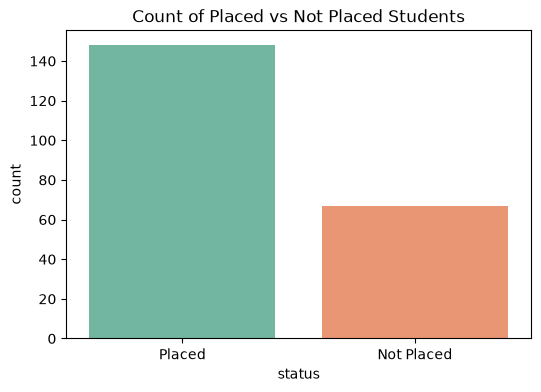

In [2]:
# Placement status ka graph
plt.figure(figsize=(6, 4))
sns.countplot(x='status', data=data, palette='Set2')
plt.title('Count of Placed vs Not Placed Students')
plt.show()

In [3]:
from sklearn.preprocessing import LabelEncoder

# 1. 'sl_no' aur 'salary' columns ko drop kar rahe hain
data_clean = data.drop(['sl_no', 'salary'], axis=1)

# 2. Text (Categorical) columns ko identify karna
categorical_columns = ['gender', 'ssc_b', 'hsc_b', 'hsc_s', 'degree_t', 'workex', 'specialisation', 'status']

# LabelEncoder ka use karke text ko numbers (0, 1, 2...) mein badalna
le = LabelEncoder()
for col in categorical_columns:
    data_clean[col] = le.fit_transform(data_clean[col])

# Saaf kiya hua data check karte hain
print("Data Cleaning aur Encoding ke baad:")
display(data_clean.head())

Data Cleaning aur Encoding ke baad:


,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status
0,1,67.00,1,91.00,1,1,58.00,2,0,55.0,1,58.80,1
1,1,79.33,0,78.33,1,2,77.48,2,1,86.5,0,66.28,1
2,1,65.00,0,68.00,0,0,64.00,0,0,75.0,0,57.80,1
3,1,56.00,0,52.00,0,2,52.00,2,0,66.0,1,59.43,0
4,1,85.80,0,73.60,0,1,73.30,0,0,96.8,0,55.50,1


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pickle

# 1. Features (X) aur Target (y) ko alag karna
X = data_clean.drop('status', axis=1) # Input features (Marks, Work Ex, etc.)
y = data_clean['status']              # Output/Target (Placed ya Not Placed)

# 2. Data ko Train (80%) aur Test (20%) mein split karna
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Models ko initialize karna
lr_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 4. Models ko train (fit) karna
lr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# 5. Predictions nikalna aur Accuracy check karna
lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

lr_acc = accuracy_score(y_test, lr_pred)
rf_acc = accuracy_score(y_test, rf_pred)

print(f"Logistic Regression Accuracy: {lr_acc * 100:.2f}%")
print(f"Random Forest Accuracy: {rf_acc * 100:.2f}%")

# 6. Model ko save karna (Flask API ke liye)
# Hum Random Forest ko save kar rahe hain kyunki ye generally better accuracy deta hai
with open('placement_model.pkl', 'wb') as file:
    pickle.dump(rf_model, file)
print("\nModel 'placement_model.pkl' ke naam se save ho gaya hai! 🎉")

Logistic Regression Accuracy: 88.37%
Random Forest Accuracy: 79.07%

Model 'placement_model.pkl' ke naam se save ho gaya hai! 🎉


In [5]:
# Best model (Logistic Regression) ko save kar rahe hain
with open('placement_model.pkl', 'wb') as file:
    pickle.dump(lr_model, file)
print("Updated! Logistic Regression model save ho gaya.")

Updated! Logistic Regression model save ho gaya.
